# 01 · Exploring MetroPT-3

**Goal:** understand how the compressor behaves, find the data problems, and decide for each failure whether it builds up **slowly (days)** or **quickly (hours)**. Your answers go into `DATA_CARD.md`, which you write at the end (section 9).

**How to use it:** run the cells top to bottom with Shift+Enter. Each section says what it does and why. Sections ending in **Check** list numbers to compare with Troshin et al. (2026), the physics paper (see `paper/notes.md`).

## 0. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works whether Jupyter starts in the repo root or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"
CSV = DATA / "MetroPT3(AirCompressor).csv"
PARQUET = DATA / "metropt3.parquet"

plt.rcParams.update({"figure.figsize": (12, 3.5), "figure.dpi": 90, "axes.grid": True})
pd.set_option("display.width", 140)

**Failure and log events.**
- Report times come from the operator's maintenance log (Troshin et al. 2026, Table 2): the moment the car was declared unavailable.
- The shaded windows are the UCI failure windows.
- Failure 5 is missing from the UCI table.
- Three other log entries are not compressor failures; the paper excludes ± 24 h around them.

In [2]:
FAILURES = pd.DataFrame(
    {
        "uci_start": ["2020-04-18 00:00", "2020-05-29 23:30", "2020-06-05 10:00", "2020-07-15 14:30", None],
        "uci_end":   ["2020-04-18 23:59", "2020-05-30 06:00", "2020-06-07 14:30", "2020-07-15 19:00", None],
        "report":    ["2020-04-18 07:05", "2020-05-30 01:10", "2020-06-05 18:00", "2020-07-15 18:25", "2020-07-17 05:46"],
    },
    index=pd.Index([1, 2, 3, 4, 5], name="failure"),
).apply(pd.to_datetime)
OTHER_LOG = pd.to_datetime(["2020-03-12", "2020-03-27", "2020-04-20"])  # not compressor failures (dates only)


def mark_events(ax, start=None, end=None):
    """Draw failure report times (red lines), UCI windows (red bands) and other log entries (grey dashes)."""
    inside = lambda t: (start is None or t >= start) and (end is None or t <= end)
    for f, row in FAILURES.iterrows():
        if inside(row["report"]):
            ax.axvline(row["report"], color="red", lw=1)
            ax.text(row["report"], 1.0, f" F{f}", color="red", fontsize=9, va="top",
                    transform=ax.get_xaxis_transform())
        if pd.notna(row["uci_start"]) and (start is None or (row["uci_end"] >= start and row["uci_start"] <= end)):
            ax.axvspan(row["uci_start"], row["uci_end"], color="red", alpha=0.12)
    for t in OTHER_LOG:
        if inside(t):
            ax.axvline(t, color="grey", ls="--", lw=1)


FAILURES

,uci_start,uci_end,report
failure,,,
1,2020-04-18 00:00:00,2020-04-18 23:59:00,2020-04-18 07:05:00
2,2020-05-29 23:30:00,2020-05-30 06:00:00,2020-05-30 01:10:00
3,2020-06-05 10:00:00,2020-06-07 14:30:00,2020-06-05 18:00:00
4,2020-07-15 14:30:00,2020-07-15 19:00:00,2020-07-15 18:25:00
5,NaT,NaT,2020-07-17 05:46:00


## 1. Load the data

Reading the 218 MB CSV takes about 20 s. We save it once as **Parquet**, a compressed column-based file format and the same one HDFS will store in step 4, so later loads take about a second.

In [3]:
if PARQUET.exists():
    df = pd.read_parquet(PARQUET)
else:
    df = pd.read_csv(CSV, parse_dates=["timestamp"], index_col="timestamp")
    df = df.rename(columns={"Unnamed: 0": "raw_idx"})
    df.to_parquet(PARQUET)

print(df.shape, "| sorted:", df.index.is_monotonic_increasing, "| duplicate times:", df.index.duplicated().sum())
print("from", df.index.min(), "to", df.index.max())
df.info(memory_usage="deep")

(1516948, 16) | sorted: True | duplicate times: 0
from 2020-02-01 00:00:00 to 2020-09-01 03:59:50
<class 'pandas.DataFrame'>
DatetimeIndex: 1516948 entries, 2020-02-01 00:00:00 to 2020-09-01 03:59:50
Data columns (total 16 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   raw_idx          1516948 non-null  int64  
 1   TP2              1516948 non-null  float64
 2   TP3              1516948 non-null  float64
 3   H1               1516948 non-null  float64
 4   DV_pressure      1516948 non-null  float64
 5   Reservoirs       1516948 non-null  float64
 6   Oil_temperature  1516948 non-null  float64
 7   Motor_current    1516948 non-null  float64
 8   COMP             1516948 non-null  float64
 9   DV_eletric       1516948 non-null  float64
 10  Towers           1516948 non-null  float64
 11  MPG              1516948 non-null  float64
 12  LPS              1516948 non-null  float64
 13  Pressure_switch  1516948 non-null  float64

In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
raw_idx,1516948.0,7584735.000,4379053.124,0.000,3792367.500,7584735.000,1.137710e+07,1.516947e+07
TP2,1516948.0,1.368,3.251,-0.032,-0.014,-0.012,-1.000000e-02,1.067600e+01
TP3,1516948.0,8.985,0.639,0.730,8.492,8.960,9.492000e+00,1.030200e+01
H1,1516948.0,7.568,3.333,-0.036,8.254,8.784,9.374000e+00,1.028800e+01
DV_pressure,1516948.0,0.056,0.382,-0.032,-0.022,-0.020,-1.800000e-02,9.844000e+00
Reservoirs,1516948.0,8.985,0.638,0.712,8.494,8.960,9.492000e+00,1.030000e+01
Oil_temperature,1516948.0,62.644,6.516,15.400,57.775,62.700,6.725000e+01,8.905000e+01
Motor_current,1516948.0,2.050,2.302,0.020,0.040,0.045,3.808000e+00,9.295000e+00
COMP,1516948.0,0.837,0.369,0.000,1.000,1.000,1.000000e+00,1.000000e+00
DV_eletric,1516948.0,0.161,0.367,0.000,0.000,0.000,0.000000e+00,1.000000e+00


**Check:**
- 1,516,948 rows, from 1 Feb to 1 Sep 2020.
- `raw_idx` grows in steps of 10: it is the original once-per-second row number, and the file keeps every 10th row.

In [5]:
df["raw_idx"].diff().value_counts().head()

raw_idx
10.0    1516947
Name: count, dtype: int64

## 2. Sampling and gaps

The time between rows should be 10 s. A longer step is a **gap**: the car was switched off (mostly at night) or the logger stopped. Gaps matter later, because a window that spans a gap mixes two different situations.

In [6]:
dt = df.index.to_series().diff().dt.total_seconds()
print("share of 10 s steps:", round((dt == 10).mean(), 4))
print(dt.value_counts().head(8))

gaps = dt[dt > 30]
gap_table = pd.DataFrame({
    "start": gaps.index - pd.to_timedelta(gaps, unit="s"),
    "end": gaps.index,
    "hours": (gaps / 3600).round(2),
})
print(len(gap_table), "gaps longer than 30 s, total", round(gap_table["hours"].sum()), "h")
gap_table.sort_values("hours", ascending=False).head(10)

share of 10 s steps: 0.8817
timestamp
10.0    1337521
9.0      128277
12.0      38321
13.0       7988
11.0       4471
21.0         10
19.0          5
22.0          4
Name: count, dtype: int64
331 gaps longer than 30 s, total 909 h


,start,end,hours
timestamp,,,
2020-04-27 01:12:49,2020-04-25 01:10:51,2020-04-27 01:12:49,48.03
2020-06-28 23:07:43,2020-06-27 10:53:07,2020-06-28 23:07:43,36.24
2020-03-01 04:00:09,2020-02-28 23:57:08,2020-03-01 04:00:09,28.05
2020-08-05 08:23:01,2020-08-04 07:42:28,2020-08-05 08:23:01,24.68
2020-05-25 01:14:14,2020-05-24 00:39:23,2020-05-25 01:14:14,24.58
2020-07-08 15:20:51,2020-07-07 15:24:51,2020-07-08 15:20:51,23.93
2020-08-23 18:51:01,2020-08-22 19:11:44,2020-08-23 18:51:01,23.65
2020-05-10 22:48:58,2020-05-10 00:31:17,2020-05-10 22:48:58,22.29
2020-06-08 11:48:04,2020-06-07 14:19:39,2020-06-08 11:48:04,21.47


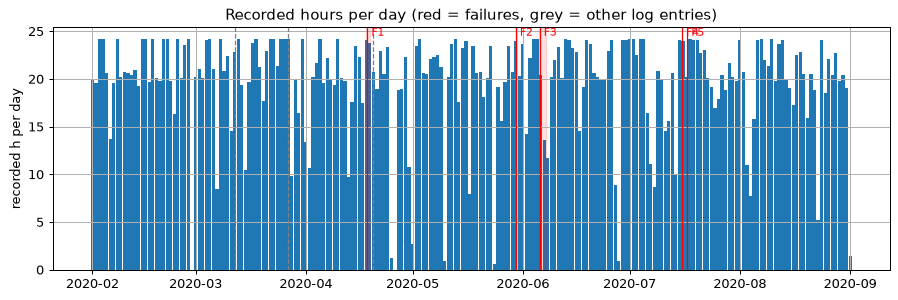

long gaps (> 1 h) usually start at hour: {1: 29, 0: 26, 19: 25}


In [7]:
hours_per_day = df["TP3"].resample("1D").count() * 10 / 3600
fig, ax = plt.subplots()
ax.bar(hours_per_day.index, hours_per_day.to_numpy(), width=0.9)
ax.set_ylabel("recorded h per day")
ax.set_title("Recorded hours per day (red = failures, grey = other log entries)")
mark_events(ax)
plt.show()

gap_start_hour = gap_table.loc[gap_table["hours"] > 1, "start"].dt.hour
print("long gaps (> 1 h) usually start at hour:", gap_start_hour.value_counts().head(3).to_dict())

**Check:** gaps mostly at night, and about 18–21 recorded hours on a normal day.

## 3. The operating cycle

The compressor has three states:

| State | How to recognise it | Motor current |
|---|---|---|
| off | motor stopped | ≈ 0 A |
| idle | motor running, not pumping air | ≈ 3.8 A |
| load | pumping air, `DV_eletric` = 1 | ≈ 5.9 A |

It starts loading when the pressure falls to about 8.1 bar, unloads at about 10.2 bar, idles for about 7 min, then stops. A **phase** is an unbroken run of one state.

In [8]:
df["state"] = pd.Categorical(
    np.select([df["Motor_current"] < 1.0, df["DV_eletric"] > 0.5], ["off", "load"], default="idle"),
    categories=["off", "idle", "load"],
)
print(df["state"].value_counts(normalize=True).round(3))
df.groupby("state", observed=True)["Motor_current"].describe().round(2)

state
off     0.546
idle    0.294
load    0.159
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
state,,,,,,,,
off,829000.0,0.04,0.01,0.02,0.04,0.04,0.04,1.00
idle,446382.0,3.79,0.21,1.00,3.72,3.76,3.83,8.68
load,241566.0,5.73,0.46,1.23,5.58,5.84,6.03,9.30


In [9]:
# A new phase starts when the state changes, or after a gap
new_phase = (df["state"] != df["state"].shift()) | (dt > 30)
df["phase_id"] = new_phase.cumsum()

phases = (
    df.assign(t=df.index)
    .groupby("phase_id")
    .agg(state=("state", "first"), start=("t", "first"), end=("t", "last"),
         n=("TP3", "size"), tp3_start=("TP3", "first"), tp3_end=("TP3", "last"))
)
phases["duration_s"] = (phases["end"] - phases["start"]).dt.total_seconds() + 10

# A phase that starts after a gap, or is followed by one, is cut short: mark it so we can leave it out
phases["after_gap"] = (dt.groupby(df["phase_id"]).first() > 30).to_numpy()
phases["clean"] = ~phases["after_gap"] & ~phases["after_gap"].shift(-1, fill_value=True)
phases["next_state"] = phases["state"].shift(-1)
print(len(phases), "phases,", int(phases["clean"].sum()), "clean")
phases.head()

42079 phases, 41438 clean


,state,start,end,n,tp3_start,tp3_end,duration_s,after_gap,clean,next_state
phase_id,,,,,,,,,,
1,off,2020-02-01 00:00:00,2020-02-01 00:22:58,140,9.358,8.078,1388.0,False,True,load
2,load,2020-02-01 00:23:08,2020-02-01 00:24:47,11,8.068,10.034,109.0,False,True,idle
3,idle,2020-02-01 00:24:57,2020-02-01 00:31:43,42,10.098,9.506,416.0,False,True,off
4,off,2020-02-01 00:31:53,2020-02-01 00:57:09,154,9.496,8.070,1526.0,False,True,load
5,load,2020-02-01 00:57:19,2020-02-01 00:58:48,10,8.066,10.064,99.0,False,True,idle


In [10]:
# The normal cycle, measured on the two calibration months (Feb–Mar) like the paper
cal = phases[phases["clean"] & (phases["start"] < "2020-04-01")]
load = cal[cal["state"] == "load"]
runon = cal[(cal["state"] == "idle") & (cal["next_state"] == "off")]
cycle = pd.Series({
    "load starts at, bar (median TP3)": load["tp3_start"].median(),
    "load ends at, bar (median TP3)": load["tp3_end"].median(),
    "load phase length, s (median)": load["duration_s"].median(),
    "pressure rise under load, bar/min": ((load["tp3_end"] - load["tp3_start"]) / load["duration_s"] * 60).median(),
    "idle run-on before the motor stops, s": runon["duration_s"].median(),
    "load phases in Feb–Mar": len(load),
}).round(3)
cycle

load starts at, bar (median TP3)            8.064
load ends at, bar (median TP3)             10.078
load phase length, s (median)             119.000
pressure rise under load, bar/min           0.961
idle run-on before the motor stops, s     416.000
load phases in Feb–Mar                   2847.000
dtype: float64

**Check against Troshin et al. (calibration months):**
- load starts at 8.09 bar and the last loaded sample is about 10.08 bar;
- the pressure rises about 1.08 bar/min under load;
- load phases last about 2 min;
- the run-on is 416 s;
- the currents are 0.04 / 3.78 / 5.92 A.

With 10 s sampling, expect differences of a few hundredths of a bar and about ± 10 s.
- The pressure rise comes out lower here (about 0.96 bar/min), because this simple version divides by the whole phase, including the first sample, taken before the pressure starts to climb. The paper fits the slope inside the phase.
- The time steps are not exactly 10 s: about 12% are 9, 11, 12 or 13 s. That is why a gap means "more than 30 s", not "more than 10 s".

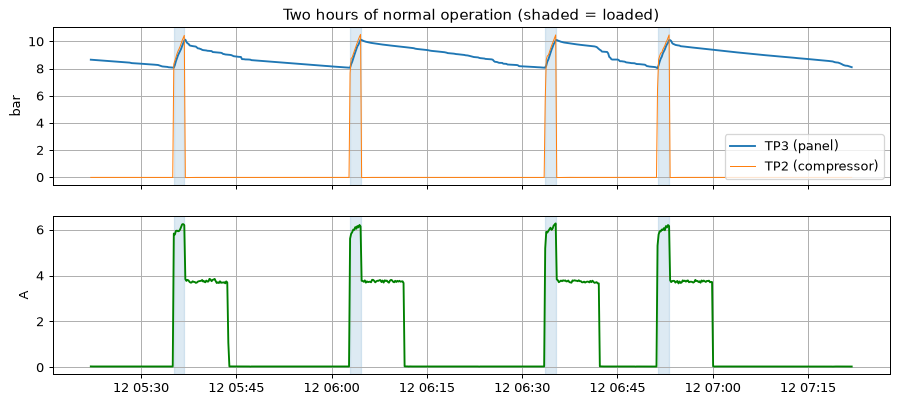

In [11]:
# Two hours of normal operation (the same window as Fig. 2a in the paper)
a, b = pd.Timestamp("2020-02-12 05:22"), pd.Timestamp("2020-02-12 07:22")
w = df.loc[a:b]
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(12, 5))
axes[0].plot(w.index, w["TP3"], label="TP3 (panel)")
axes[0].plot(w.index, w["TP2"], label="TP2 (compressor)", lw=0.8)
axes[0].set_ylabel("bar"); axes[0].legend(loc="lower right")
axes[1].plot(w.index, w["Motor_current"], color="green"); axes[1].set_ylabel("A")
for _, p in phases[(phases["state"] == "load") & phases["start"].between(a, b)].iterrows():
    for ax in axes:
        ax.axvspan(p["start"], p["end"], color="tab:blue", alpha=0.15)
axes[0].set_title("Two hours of normal operation (shaded = loaded)")
plt.show()

## 4. Frozen pressure sensor

Troshin et al. found that TP3 sometimes stops changing for hours while the compressor keeps working: a stuck sensor. The pipeline must flag this and must never train on it. A healthy TP3 changes at almost every 10 s step.

In [12]:
same = df["TP3"].diff().eq(0)   # unchanged since the previous row. Gaps are ignored on purpose:
run_id = (~same).cumsum()       # a stuck sensor keeps its value across a gap
runs = (
    df.assign(t=df.index, motor_on=df["Motor_current"] > 1)
    .groupby(run_id)
    .agg(start=("t", "first"), end=("t", "last"), rows=("TP3", "size"),
         value=("TP3", "first"), motor_on=("motor_on", "mean"))
)
runs["recorded_h"] = runs["rows"] * 10 / 3600
runs["wall_h"] = (runs["end"] - runs["start"]).dt.total_seconds() / 3600

FROZEN_MIN_H = 0.5   # 30 min, as in the paper's frozen-sensor guard
frozen = runs[(runs["recorded_h"] >= FROZEN_MIN_H) & (runs["motor_on"] > 0.1)].sort_values("start")
df["tp3_frozen"] = run_id.isin(frozen.index).to_numpy()
print(len(frozen), "frozen periods of 30 min or more;", int((frozen["recorded_h"] >= 1).sum()), "of 1 h or more;",
      "rows flagged:", int(df["tp3_frozen"].sum()))
frozen.round({"motor_on": 2, "recorded_h": 2, "wall_h": 2})

4 frozen periods of 30 min or more; 3 of 1 h or more; rows flagged: 26814


,start,end,rows,value,motor_on,recorded_h,wall_h
TP3,,,,,,,
529647,2020-04-13 18:29:10,2020-04-13 19:27:16,291,10.140,1.0,0.81,0.97
572963,2020-04-20 04:49:07,2020-04-21 01:16:52,6110,9.728,1.0,16.97,20.46
985810,2020-06-22 15:06:11,2020-06-25 05:08:35,18515,8.506,1.0,51.43,62.04
1173118,2020-07-22 06:43:34,2020-07-22 13:04:24,1898,10.042,1.0,5.27,6.35


**Check:** the paper reports seven periods of 1 h or more between April and August, the longest (62 h of wall time) on 22–25 June.
- This code finds the 62 h period exactly, but only three of 1 h or more, even when small changes in TP3 are allowed. The difference is an open question, and exercise (a) in section 9.
- One frozen period covers 20 April, the date of a maintenance-log entry that was *not* a compressor failure. The log entry may have been this sensor.

## 5. Two health signals

**(a) Load share:** the fraction of a recorded hour spent loaded. A leak makes the compressor work more. The "duty rule" (baseline L1 in the paper) raises an alarm when the load share exceeds 0.5.

**(b) Idle pressure-fall rate:** how fast the pressure drops while the compressor is *not* pumping. That drop is the air being used (by consumers, plus any leak), so it is a direct leak signal. Following the paper: in each unloaded phase of at least 600 s, skip the first 300 s (the air is still cooling after compression), then fit a straight line to TP3.

In [13]:
rec = df["TP3"].resample("1h").count()                       # rows recorded in each hour
load_share = (df["state"] == "load").resample("1h").mean()
load_share = load_share[rec >= 180].rename("load_share")     # keep hours that are at least half recorded

loaded = df["DV_eletric"] > 0.5
uph = ((loaded != loaded.shift()) | (dt > 30)).cumsum()     # runs of loaded / unloaded, cut at gaps
t = df.index.to_series()
start = t.groupby(uph).transform("first")
end = t.groupby(uph).transform("last")
since = (t - start).dt.total_seconds()
length = (end - start).dt.total_seconds() + 10

use = (~loaded) & (length >= 600) & (since >= 300) & ~df["tp3_frozen"]
x, y = since[use].to_numpy(), df.loc[use, "TP3"].to_numpy()
fit = (pd.DataFrame({"g": uph[use].to_numpy(), "x": x, "y": y, "xx": x * x, "xy": x * y})
       .groupby("g").agg(n=("x", "size"), sx=("x", "sum"), sy=("y", "sum"), sxx=("xx", "sum"), sxy=("xy", "sum")))
fit = fit[fit["n"] >= 5]
fit["slope"] = (fit["n"] * fit["sxy"] - fit["sx"] * fit["sy"]) / (fit["n"] * fit["sxx"] - fit["sx"] ** 2)  # bar per s
fit["end"] = end.groupby(uph).first().loc[fit.index].to_numpy()
idle_fall = pd.Series(-fit["slope"].to_numpy() * 60, index=pd.DatetimeIndex(fit["end"]), name="idle_fall").sort_index()

print(len(idle_fall), "unloaded phases measured")
print("Feb–Mar median idle fall:", round(idle_fall[:"2020-03-31"].median(), 4), "bar/min")
print("Feb–Mar median load share:", round(load_share[:"2020-03-31"].median(), 3))

9857 unloaded phases measured
Feb–Mar median idle fall: 0.0688 bar/min
Feb–Mar median load share: 0.072


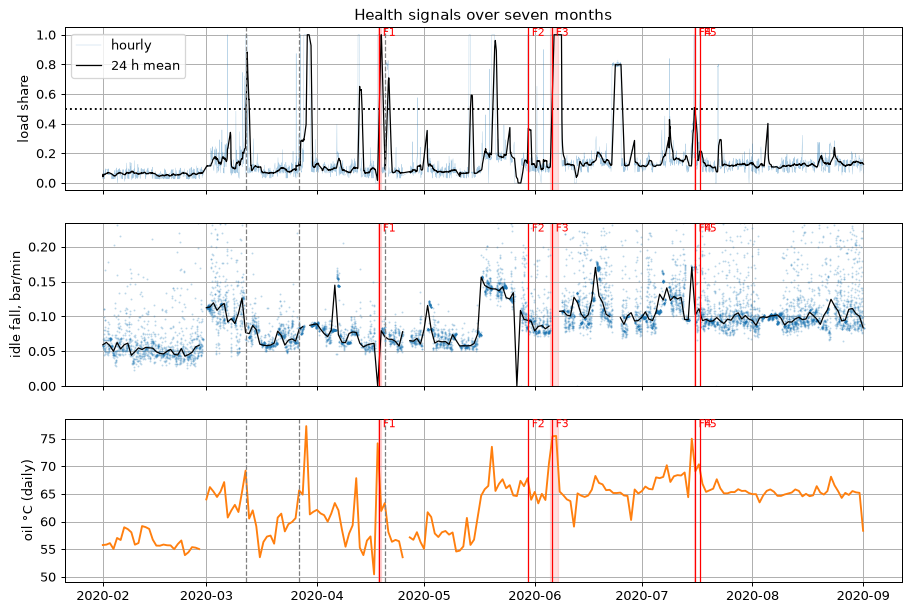

In [14]:
ls24 = load_share.rolling("24h").mean()
fall_day = idle_fall.resample("1D").median()
oil_day = df["Oil_temperature"].resample("1D").mean()

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(12, 8))
axes[0].plot(load_share.index, load_share.to_numpy(), lw=0.3, alpha=0.4, label="hourly")
axes[0].plot(ls24.index, ls24.to_numpy(), color="k", lw=1, label="24 h mean")
axes[0].axhline(0.5, color="k", ls=":"); axes[0].set_ylabel("load share"); axes[0].legend(loc="upper left")
axes[1].plot(idle_fall.index, idle_fall.to_numpy(), ".", ms=1, alpha=0.3)
axes[1].plot(fall_day.index, fall_day.to_numpy(), color="k", lw=1)
axes[1].set_ylim(0, idle_fall.quantile(0.995)); axes[1].set_ylabel("idle fall, bar/min")
axes[2].plot(oil_day.index, oil_day.to_numpy(), color="tab:orange"); axes[2].set_ylabel("oil °C (daily)")
for ax in axes:
    mark_events(ax)
axes[0].set_title("Health signals over seven months")
plt.show()

**Check:**
- In Feb–Mar the idle pressure fall should be close to 0.069 bar/min.
- The paper sees summer consumption slightly above February's: normal drift.
- Peaks should sit near the failures.

## 6. Around each failure

For each failure, the plots cover 7 days before to 1 day after the report time.
- **Green band:** the warning zone (7 days to 2 h before the report). An alarm that starts here counts as a useful warning.
- **Red band:** the UCI failure window.
- **Grey band (top panel):** TP3 frozen.

**Your questions:** when does each signal start to move? Is the build-up slow (days) or fast (hours)?

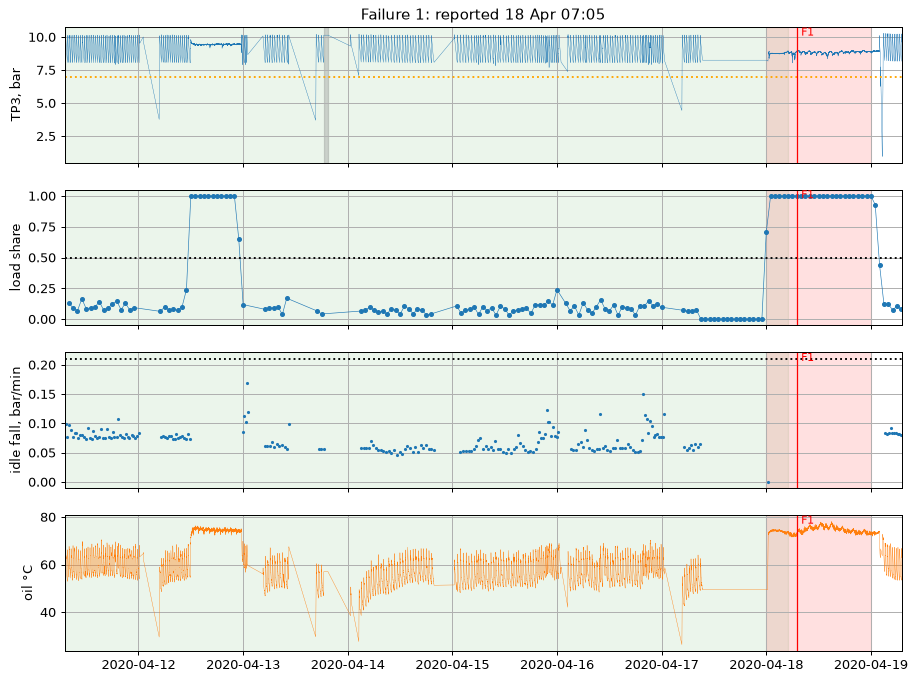

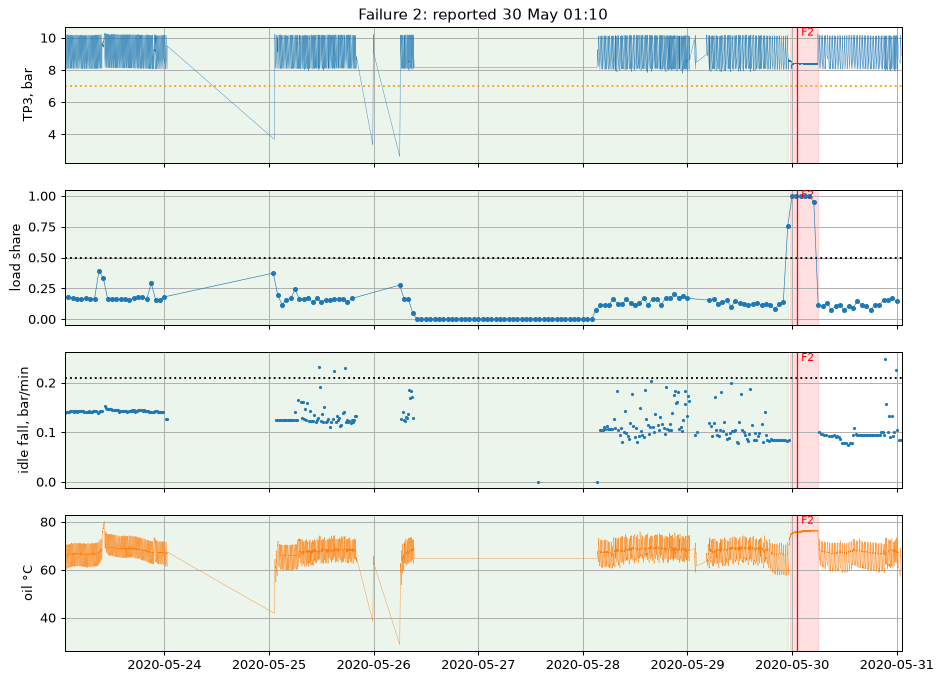

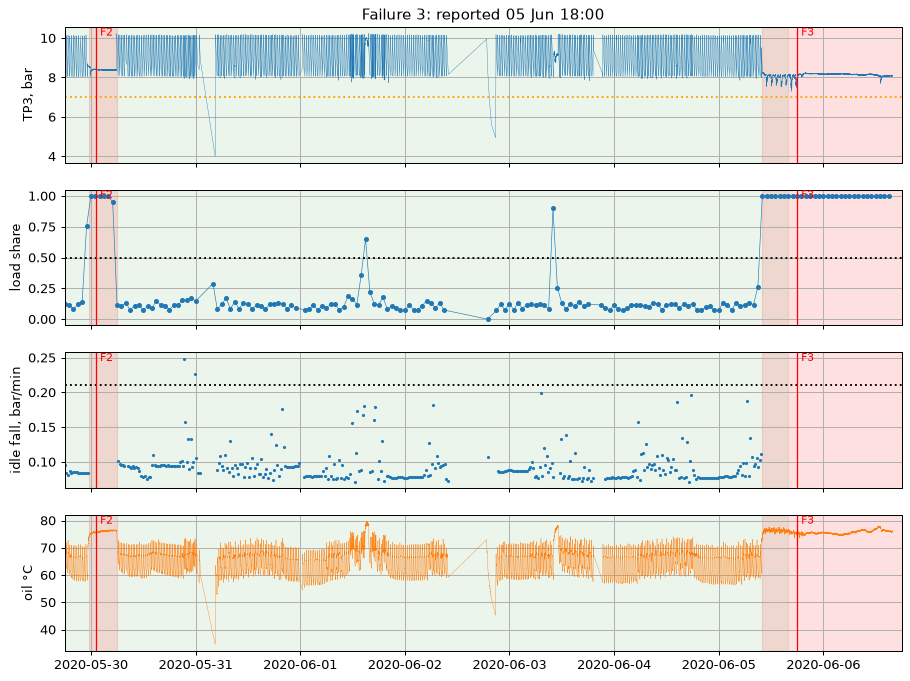

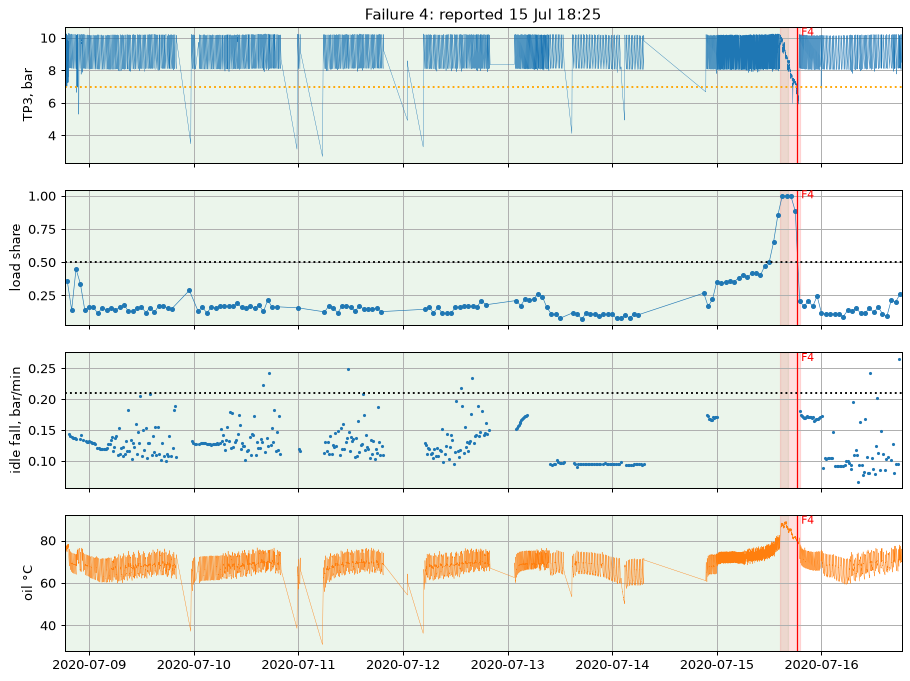

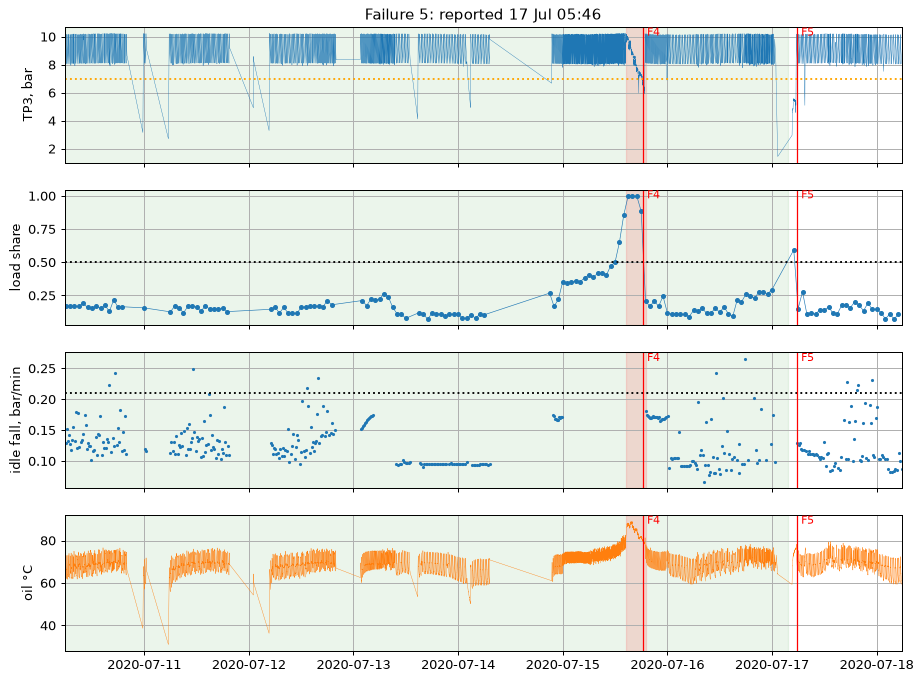

In [15]:
fall_p99 = idle_fall[:"2020-03-31"].quantile(0.99)


def plot_failure(f, days_before=7, days_after=1):
    tf = FAILURES.loc[f, "report"]
    a, b = tf - pd.Timedelta(days=days_before), tf + pd.Timedelta(days=days_after)
    w = df.loc[a:b]
    fig, axes = plt.subplots(4, 1, sharex=True, figsize=(12, 9))
    axes[0].plot(w.index, w["TP3"], lw=0.3); axes[0].axhline(7, color="orange", ls=":"); axes[0].set_ylabel("TP3, bar")
    ls = load_share[a:b]
    axes[1].plot(ls.index, ls.to_numpy(), marker=".", lw=0.5); axes[1].axhline(0.5, color="k", ls=":")
    axes[1].set_ylabel("load share")
    fall = idle_fall[a:b]
    axes[2].plot(fall.index, fall.to_numpy(), ".", ms=3); axes[2].axhline(fall_p99, color="k", ls=":")
    axes[2].set_ylabel("idle fall, bar/min")
    axes[3].plot(w.index, w["Oil_temperature"], lw=0.3, color="tab:orange"); axes[3].set_ylabel("oil °C")
    for ax in axes:
        ax.axvspan(tf - pd.Timedelta(days=7), tf - pd.Timedelta(hours=2), color="green", alpha=0.08)
        mark_events(ax, a, b)
        ax.set_xlim(a, b)
    for _, r in frozen[(frozen["end"] >= a) & (frozen["start"] <= b)].iterrows():
        axes[0].axvspan(r["start"], r["end"], color="grey", alpha=0.3)
    axes[0].set_title(f"Failure {f}: reported {tf:%d %b %H:%M}")
    plt.show()


for f in FAILURES.index:
    plot_failure(f)

**A rough first-crossing table** (dotted lines in the plots):
- the first hour in the warning zone with load share above 0.5 (the duty rule);
- the first unloaded phase with an idle fall above the Feb–Mar 99th percentile.

It is crude: one noisy hour early in the zone looks like a 160 h warning. The "hours above" columns show whether the signal *stays* high. Judge slow or fast from the plots, not from this table alone.

The paper's duty-rule leads for failures 1–4 were 139, 159, 162 and 40 h, and this table reproduces the first three.
- **Failure 4 shows 168 h here** because an alarm episode was already running when its warning zone opened. The paper only counts episodes that *start* inside the zone, so it found the next one, 40 h before.
- **The duty rule also fires after every overnight standstill**, while the reservoirs refill. That is why it has so many false alarms (5.7 per 1000 h in the paper).

In [16]:
# The duty rule as the paper computes it: load share over the last hour, at every sample,
# counted only when at least 30 min of that hour is recorded
is_load = (df["state"] == "load").astype(float)
duty_roll = is_load.rolling("1h").mean()[is_load.rolling("1h").count() >= 180]

rows = []
for f, r in FAILURES.iterrows():
    tf = r["report"]
    z0, z1 = tf - pd.Timedelta(days=7), tf - pd.Timedelta(hours=2)
    duty, fall = duty_roll[z0:z1], idle_fall[z0:z1]
    first_duty, first_fall = duty[duty > 0.5].index.min(), fall[fall > fall_p99].index.min()
    hours = lambda t0: round((tf - t0) / pd.Timedelta(hours=1), 1) if pd.notna(t0) else None
    rows.append({
        "failure": f,
        "duty > 0.5 first, h before": hours(first_duty),
        "hours with duty > 0.5": round((duty > 0.5).sum() * 10 / 3600, 1),
        "idle fall > p99 first, h before": hours(first_fall),
        "phases with fall > p99": int((fall > fall_p99).sum()),
        "max load share in zone": round(duty.max(), 2),
    })
pd.DataFrame(rows).set_index("failure")

,"duty > 0.5 first, h before",hours with duty > 0.5,"idle fall > p99 first, h before",phases with fall > p99,max load share in zone
failure,,,,,
1,138.8,16.3,NaN,0,1.00
2,159.1,0.7,109.7,3,0.59
3,162.3,14.8,140.6,2,1.00
4,168.0,5.0,122.5,5,1.00
5,41.2,6.6,157.8,7,1.00


## 7. Normal drift: winter against summer

Compare a February week with the clean summer week the paper used (29 Jun – 5 Jul 2020, outside every failure zone). Changes between two *healthy* weeks are normal drift: the kind a retraining policy **should** follow.

In [17]:
def week_stats(a, b):
    w = df.loc[a:b]
    rec_h = len(w) * 10 / 3600
    in_week = phases["start"].between(pd.Timestamp(a), pd.Timestamp(b))
    return pd.Series({
        "recorded h": rec_h,
        "oil temperature mean, °C": w["Oil_temperature"].mean(),
        "load share": (w["state"] == "load").mean(),
        "load phases per recorded h": ((phases["state"] == "load") & in_week).sum() / rec_h,
        "idle fall median, bar/min": idle_fall[a:b].median(),
        "TP3 frozen, h": w["tp3_frozen"].sum() * 10 / 3600,
    })


pd.DataFrame({
    "Feb 10–16": week_stats("2020-02-10", "2020-02-16 23:59:59"),
    "Jun 29 – Jul 5": week_stats("2020-06-29", "2020-07-05 23:59:59"),
}).round(3)

,Feb 10–16,Jun 29 – Jul 5
recorded h,150.400,167.497
"oil temperature mean, °C",57.236,66.049
load share,0.060,0.121
load phases per recorded h,1.908,3.051
"idle fall median, bar/min",0.054,0.101
"TP3 frozen, h",0.000,0.000


## 8. Save what later steps reuse

These files go in `data/`, which Git ignores.

In [18]:
phases.to_parquet(DATA / "phases.parquet")
idle_fall.to_frame().to_parquet(DATA / "idle_fall.parquet")
load_share.to_frame().to_parquet(DATA / "load_share_hourly.parquet")
df[["tp3_frozen"]].to_parquet(DATA / "tp3_frozen.parquet")
print("saved:", sorted(p.name for p in DATA.glob("*.parquet")))

saved: ['idle_fall.parquet', 'load_share_hourly.parquet', 'metropt3.parquet', 'phases.parquet', 'tp3_frozen.parquet']


## 9. Your turn

**1. Write `DATA_CARD.md`** in the repo root, from the outputs above. Use this outline:

```
# MetroPT-3 data card
## Sampling and coverage
## Gaps
## Normal operating cycle (Feb–Mar)
## Data-quality problems (frozen TP3, ...)
## Normal drift (winter vs summer)
## Failures: slow or fast?
| Failure | Report time | First sign (h before) | Slow or fast | Evidence |
## What this means for the pipeline and the paper
```

**2. Three short exercises**, to make the code yours:
- (a) Change `FROZEN_MIN_H` to 0.25 (15 min) and re-run section 4. How many more periods are there? Which threshold would you use in the live pipeline, and why?
- (b) The paper found no leak in the 24 h before failure 1 (Table 8). Do your plots agree? What else could explain the duty rule firing days earlier?
- (c) Failures 4 and 5 are 1.5 days apart. Is that one fault or two? Look at the plots between them.